In [ ]:

import sys
import torch
import platform

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Platform:", platform.platform())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
        "GB"
    )
else:
    print("WARNING: GPU not available!")


Python: 3.13.16
PyTorch: 2.14.1+cu130
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
CUDA available: True
GPU: Tesla T4
GPU memory: 15.64 GB


In [ ]:

!git clone https://github.com/karpathy/nanoGPT.git /content/nanoGPT

%cd /content/nanoGPT

!git rev-parse HEAD

!ls


Cloning into '/content/nanoGPT'...
remote: Enumerating objects: 689, done.
remote: Total 689 (delta 0), reused 0 (delta 0), pack-reused 689 (from 1)
Receiving objects: 100% (689/689), 981.26 KiB | 14.22 MiB/s, done.
Resolving deltas: 100% (380/380), done.
/content/nanoGPT
3adf61e154c3fe3fca428ad6bc3818b27a3b8291
assets	  configurator.py  model.py   scaling_laws.ipynb
bench.py  data		   README.md  train.py
config	  LICENSE	   sample.py  transformer_sizing.ipynb


In [ ]:

%cd /content/nanoGPT

!pip install -q numpy transformers datasets tiktoken wandb tqdm

print("Dependencies installation completed!")


/content/nanoGPT
Dependencies installation completed!


In [ ]:

%cd /content/nanoGPT

!python data/shakespeare_char/prepare.py

from pathlib import Path

data_dir = Path("/content/nanoGPT/data/shakespeare_char")

print("\nDataset files:")
for filename in ["train.bin", "val.bin", "meta.pkl"]:
    file_path = data_dir / filename
    print(f"{filename}: {'Found' if file_path.exists() else 'Missing'}")


/content/nanoGPT
length of dataset in characters: 1,115,394
all the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
vocab size: 65
train has 1,003,854 tokens
val has 111,540 tokens

Dataset files:
train.bin: Found
val.bin: Found
meta.pkl: Found


In [ ]:

import random
import numpy as np
import torch

SEED = 1337

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))


Random seed set to: 1337
CUDA available: True
GPU: Tesla T4


In [ ]:

from pathlib import Path

ROOT = Path("/content/nanoGPT")
RESULTS = ROOT / "experiment_results"

folders = [
    "configs",
    "logs",
    "checkpoints",
    "samples",
    "plots"
]

RESULTS.mkdir(parents=True, exist_ok=True)

for folder in folders:
    (RESULTS / folder).mkdir(parents=True, exist_ok=True)

print("Experiment directory:", RESULTS)
print("\nCreated folders:")

for folder in folders:
    print(f"{folder}: {(RESULTS / folder).exists()}")


Experiment directory: /content/nanoGPT/experiment_results

Created folders:
configs: True
logs: True
checkpoints: True
samples: True
plots: True


In [ ]:

import itertools
import pandas as pd

hyperparameters = {
    "block_size": [64, 128],
    "n_layer": [4, 6],
    "n_head": [4, 8],
    "n_embd": [128, 256],
    "batch_size": [8, 16],
    "max_iters": [1000, 2000],
    "dropout": [0.1, 0.2]
}

keys = list(hyperparameters.keys())

combinations = list(
    itertools.product(*hyperparameters.values())
)

experiments = pd.DataFrame(combinations, columns=keys)

experiments.insert(
    0,
    "experiment_id",
    [f"exp_{i:03d}" for i in range(1, len(experiments) + 1)]
)

experiments["status"] = "not_started"

csv_path = RESULTS / "all_experiments.csv"
experiments.to_csv(csv_path, index=False)

print("Total experiments:", len(experiments))
print("Block size 64:", (experiments["block_size"] == 64).sum())
print("Block size 128:", (experiments["block_size"] == 128).sum())
print("CSV saved:", csv_path)

display(experiments.head(10))


Total experiments: 128
Block size 64: 64
Block size 128: 64
CSV saved: /content/nanoGPT/experiment_results/all_experiments.csv


,experiment_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,status
0,exp_001,64,4,4,128,8,1000,0.1,not_started
1,exp_002,64,4,4,128,8,1000,0.2,not_started
2,exp_003,64,4,4,128,8,2000,0.1,not_started
3,exp_004,64,4,4,128,8,2000,0.2,not_started
4,exp_005,64,4,4,128,16,1000,0.1,not_started
5,exp_006,64,4,4,128,16,1000,0.2,not_started
6,exp_007,64,4,4,128,16,2000,0.1,not_started
7,exp_008,64,4,4,128,16,2000,0.2,not_started
8,exp_009,64,4,4,256,8,1000,0.1,not_started
9,exp_010,64,4,4,256,8,1000,0.2,not_started


In [ ]:

from pathlib import Path

ROOT = Path("/content/nanoGPT")

required_files = ["model.py", "train.py", "sample.py"]

for filename in required_files:
    path = ROOT / filename
    print(f"{filename}: {'Found' if path.is_file() else 'Missing'}")

print("\nExperiment CSV:", (ROOT / "experiment_results/all_experiments.csv").exists())


model.py: Found
train.py: Found
sample.py: Found

Experiment CSV: True


In [ ]:

%cd /content/nanoGPT

print("========== MODEL.PY ==========")
!grep -nE "class CausalSelfAttention|class Block|class GPTConfig|class GPT" model.py

print("\n========== TRAIN.PY ==========")
!grep -nE "gradient_accumulation_steps|batch_size =|def get_batch|def get_lr|lossf" train.py

print("\n========== SAMPLE.PY ==========")
!grep -nE "max_new_tokens|temperature|top_k|model.generate" sample.py


/content/nanoGPT
========== MODEL.PY ==========
29:class CausalSelfAttention(nn.Module):
94:class Block(nn.Module):
109:class GPTConfig:
118:class GPT(nn.Module):

========== TRAIN.PY ==========
48:gradient_accumulation_steps = 5 * 8 # used to simulate larger batch sizes
49:batch_size = 12 # if gradient_accumulation_steps > 1, this is the micro-batch size
94:    assert gradient_accumulation_steps % ddp_world_size == 0
95:    gradient_accumulation_steps //= ddp_world_size
101:tokens_per_iter = gradient_accumulation_steps * ddp_world_size * batch_size * block_size
116:def get_batch(split):
231:def get_lr(it):
292:    for micro_step in range(gradient_accumulation_steps):
298:            model.require_backward_grad_sync = (micro_step == gradient_accumulation_steps - 1)
301:            loss = loss / gradient_accumulation_steps # scale the loss to account for gradient accumulation
323:        lossf = loss.item() * gradient_accumulation_steps
325:            mfu = raw_model.estimate_mfu(batch

In [13]:

from pathlib import Path
from google.colab import files

RESULTS = Path("/content/nanoGPT/experiment_results")
csv_path = RESULTS / "all_experiments.csv"

print("Experiment CSV exists:", csv_path.exists())

if csv_path.exists():
    files.download(str(csv_path))
    print("Download requested successfully!")
else:
    print("File missing. We need to restore the configurations.")


Experiment CSV exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download requested successfully!


In [14]:

import pandas as pd
from pathlib import Path
from google.colab import files

RESULTS = Path("/content/nanoGPT/experiment_results")

experiments = pd.read_csv(RESULTS / "all_experiments.csv")

member1 = experiments[experiments["block_size"] == 64].copy()
member2 = experiments[experiments["block_size"] == 128].copy()

assert len(member1) == 64
assert len(member2) == 64

member1_path = RESULTS / "member1_experiments.csv"
member2_path = RESULTS / "member2_experiments.csv"

member1.to_csv(member1_path, index=False)
member2.to_csv(member2_path, index=False)

print("Member 1 experiments:", len(member1))
print("Member 2 experiments:", len(member2))
print("Total experiments:", len(member1) + len(member2))

print("\nDownloading both files...")
files.download(str(member1_path))
files.download(str(member2_path))


Member 1 experiments: 64
Member 2 experiments: 64
Total experiments: 128



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

import subprocess
import time

# Remove both unsupported seed arguments
command = [
    arg for arg in command
    if not arg.startswith(("--seed=", "--seed_offset="))
]

print("Starting corrected GPU training test...")

start_time = time.time()

result = subprocess.run(
    command,
    cwd=str(ROOT),
    capture_output=True,
    text=True
)

print(result.stdout[-8000:])

if result.returncode != 0:
    print("\nERROR:")
    print(result.stderr[-5000:])

print("\nReturn code:", result.returncode)
print("Elapsed time:", round(time.time() - start_time, 2), "seconds")
print("Checkpoint exists:", (test_dir / "ckpt.pt").exists())


Starting corrected GPU training test...
Overriding: dataset = shakespeare_char
Overriding: init_from = scratch
Overriding: out_dir = /content/nanoGPT/experiment_results/checkpoints/smoke_test
Overriding: block_size = 64
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: batch_size = 8
Overriding: dropout = 0.1
Overriding: max_iters = 10
Overriding: gradient_accumulation_steps = 1
Overriding: eval_interval = 5
Overriding: eval_iters = 2
Overriding: log_interval = 1
Overriding: always_save_checkpoint = True
Overriding: wandb_log = False
Overriding: compile = False
Overriding: device = cuda
Overriding: dtype = float16
tokens per iteration will be: 512
found vocab_size = 65 (inside data/shakespeare_char/meta.pkl)
Initializing a new model from scratch
number of parameters: 0.80M
num decayed parameter tensors: 18, with 802,944 parameters
num non-decayed parameter tensors: 9, with 1,152 parameters
using fused AdamW: True
step 0: train loss 4.1693, val loss 4.1

In [18]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/nanoGPT")
RESULTS = ROOT / "experiment_results"

required_paths = {
    "All 128 configurations": RESULTS / "all_experiments.csv",
    "Your 64 configurations": RESULTS / "member1_experiments.csv",
    "Teammate's 64 configurations": RESULTS / "member2_experiments.csv",
    "Smoke-test checkpoint": RESULTS / "checkpoints/smoke_test/ckpt.pt",
    "Training script": ROOT / "train.py",
    "Sampling script": ROOT / "sample.py"
}

print("EXPERIMENT FILE VERIFICATION")
print("-" * 45)

for name, path in required_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

member1 = pd.read_csv(RESULTS / "member1_experiments.csv")

print("\nYour total experiments:", len(member1))
print("First experiment:", member1.iloc[0]["experiment_id"])
print("Last experiment:", member1.iloc[-1]["experiment_id"])
print("All not started:", (member1["status"] == "not_started").all())


EXPERIMENT FILE VERIFICATION
---------------------------------------------
All 128 configurations: FOUND
Your 64 configurations: FOUND
Teammate's 64 configurations: FOUND
Smoke-test checkpoint: FOUND
Training script: FOUND
Sampling script: FOUND

Your total experiments: 64
First experiment: exp_001
Last experiment: exp_064
All not started: True


In [19]:

import subprocess
import time
import re
import json
from pathlib import Path

ROOT = Path("/content/nanoGPT")
RESULTS = ROOT / "experiment_results"

def run_experiment(config, test_mode=False):
    exp_id = str(config["experiment_id"])

    checkpoint_dir = RESULTS / "checkpoints" / exp_id
    log_dir = RESULTS / "logs"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    log_dir.mkdir(parents=True, exist_ok=True)

    max_iters = 10 if test_mode else int(config["max_iters"])

    command = [
        "python", "train.py",
        "--dataset=shakespeare_char",
        "--init_from=scratch",
        f"--out_dir={checkpoint_dir}",
        f"--block_size={int(config['block_size'])}",
        f"--n_layer={int(config['n_layer'])}",
        f"--n_head={int(config['n_head'])}",
        f"--n_embd={int(config['n_embd'])}",
        f"--batch_size={int(config['batch_size'])}",
        f"--dropout={float(config['dropout'])}",
        f"--max_iters={max_iters}",
        "--gradient_accumulation_steps=1",
        "--eval_interval=100",
        "--eval_iters=20",
        "--log_interval=10",
        "--always_save_checkpoint=True",
        "--wandb_log=False",
        "--compile=False",
        "--device=cuda",
        "--dtype=float16"
    ]

    if test_mode:
        command = [
            arg if not arg.startswith("--eval_interval=")
            else "--eval_interval=5"
            for arg in command
        ]

    print(f"Starting {exp_id} | iterations={max_iters}")

    start = time.time()

    with open(log_dir / f"{exp_id}.log", "w") as log_file:
        process = subprocess.run(
            command,
            cwd=str(ROOT),
            stdout=log_file,
            stderr=subprocess.STDOUT,
            text=True
        )

    elapsed = round(time.time() - start, 2)

    log_text = (log_dir / f"{exp_id}.log").read_text()

    losses = re.findall(
        r"step (\d+): train loss ([\d.]+), val loss ([\d.]+)",
        log_text
    )

    final_train_loss = float(losses[-1][1]) if losses else None
    final_val_loss = float(losses[-1][2]) if losses else None

    result = {
        "experiment_id": exp_id,
        "status": "completed" if process.returncode == 0 else "failed",
        "max_iters": max_iters,
        "training_time_seconds": elapsed,
        "final_train_loss": final_train_loss,
        "final_val_loss": final_val_loss,
        "checkpoint_saved": (checkpoint_dir / "ckpt.pt").exists()
    }

    result_path = log_dir / f"{exp_id}_summary.json"
    result_path.write_text(json.dumps(result, indent=4))

    print(json.dumps(result, indent=4))

    if process.returncode != 0:
        print("\nError details:")
        print(log_text[-3000:])

    return result

print("Training runner created successfully!")


Training runner created successfully!


In [20]:

# Load the first experiment configuration
test_config = member1.iloc[0].copy()

# Give the test a separate ID
test_config["experiment_id"] = "runner_test_001"

# Run only 10 iterations
test_result = run_experiment(
    test_config,
    test_mode=True
)

print("\nTEST VERIFICATION")
print("Status:", test_result["status"])
print("Checkpoint saved:", test_result["checkpoint_saved"])
print("Training time:", test_result["training_time_seconds"], "seconds")


Starting runner_test_001 | iterations=10
{
    "experiment_id": "runner_test_001",
    "status": "completed",
    "max_iters": 10,
    "training_time_seconds": 4.76,
    "final_train_loss": 4.1467,
    "final_val_loss": 4.1389,
    "checkpoint_saved": true
}

TEST VERIFICATION
Status: completed
Checkpoint saved: True
Training time: 4.76 seconds


In [21]:

import shutil
from pathlib import Path
from google.colab import files

ROOT = Path("/content/nanoGPT")
RESULTS = ROOT / "experiment_results"

def backup_results():
    backup_folder = Path("/content/nanoGPT_backup")

    if backup_folder.exists():
        shutil.rmtree(backup_folder)

    backup_folder.mkdir(parents=True, exist_ok=True)

    # Copy configuration CSV files
    for csv_file in RESULTS.glob("*.csv"):
        shutil.copy2(csv_file, backup_folder / csv_file.name)

    # Copy experiment logs and summaries
    if (RESULTS / "logs").exists():
        shutil.copytree(
            RESULTS / "logs",
            backup_folder / "logs"
        )

    # Copy configuration files
    if (RESULTS / "configs").exists():
        shutil.copytree(
            RESULTS / "configs",
            backup_folder / "configs"
        )

    zip_path = shutil.make_archive(
        "/content/nanoGPT_backup",
        "zip",
        root_dir=backup_folder
    )

    print("Backup created:", zip_path)
    print("Backup size:", round(Path(zip_path).stat().st_size / 1e6, 2), "MB")

    files.download(zip_path)

print("Backup function created successfully!")


Backup function created successfully!


In [22]:

import pandas as pd

# Load your 64 experiment configurations
member1 = pd.read_csv(
    "/content/nanoGPT/experiment_results/member1_experiments.csv"
)

# Select the first experiment
config = member1.iloc[0]

print("Experiment:", config["experiment_id"])
print("Training iterations:", config["max_iters"])
print("Starting full training...\n")

# Run the actual experiment (not test mode)
result_001 = run_experiment(config, test_mode=False)

print("\nFINAL VERIFICATION")
print("Status:", result_001["status"])
print("Training loss:", result_001["final_train_loss"])
print("Validation loss:", result_001["final_val_loss"])
print("Execution time:", result_001["training_time_seconds"], "seconds")
print("Checkpoint saved:", result_001["checkpoint_saved"])


Experiment: exp_001
Training iterations: 1000
Starting full training...

Starting exp_001 | iterations=1000
{
    "experiment_id": "exp_001",
    "status": "completed",
    "max_iters": 1000,
    "training_time_seconds": 16.11,
    "final_train_loss": 2.4237,
    "final_val_loss": 2.4423,
    "checkpoint_saved": true
}

FINAL VERIFICATION
Status: completed
Training loss: 2.4237
Validation loss: 2.4423
Execution time: 16.11 seconds
Checkpoint saved: True


In [23]:

import pandas as pd
from pathlib import Path

RESULTS = Path("/content/nanoGPT/experiment_results")
tracker_path = RESULTS / "member1_experiments.csv"

tracker = pd.read_csv(tracker_path)

# Add result columns if they do not exist
for column in [
    "training_time_seconds",
    "final_train_loss",
    "final_val_loss",
    "checkpoint_saved"
]:
    if column not in tracker.columns:
        tracker[column] = None

# Update exp_001
mask = tracker["experiment_id"] == "exp_001"

tracker.loc[mask, "status"] = result_001["status"]
tracker.loc[mask, "training_time_seconds"] = result_001["training_time_seconds"]
tracker.loc[mask, "final_train_loss"] = result_001["final_train_loss"]
tracker.loc[mask, "final_val_loss"] = result_001["final_val_loss"]
tracker.loc[mask, "checkpoint_saved"] = result_001["checkpoint_saved"]

# Save updated tracker
tracker.to_csv(tracker_path, index=False)

print("Tracker updated successfully!")
print("Completed experiments:", (tracker["status"] == "completed").sum())
print("Remaining experiments:", (tracker["status"] == "not_started").sum())

display(tracker.loc[mask])


Tracker updated successfully!
Completed experiments: 1
Remaining experiments: 63


,experiment_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,status,training_time_seconds,final_train_loss,final_val_loss,checkpoint_saved
0,exp_001,64,4,4,128,8,1000,0.1,completed,16.11,2.4237,2.4423,True


In [24]:

# Create and download the experiment backup
backup_results()

print("\nBackup process completed!")


Backup created: /content/nanoGPT_backup.zip
Backup size: 0.01 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Backup process completed!


In [25]:

import pandas as pd
from pathlib import Path

RESULTS = Path("/content/nanoGPT/experiment_results")
tracker_path = RESULTS / "member1_experiments.csv"

def run_batch(batch_size=3):
    tracker = pd.read_csv(tracker_path)

    pending = tracker[
        tracker["status"] != "completed"
    ].head(batch_size)

    print("Experiments to run:", len(pending))

    for _, config in pending.iterrows():
        exp_id = config["experiment_id"]

        print(f"\n{'=' * 45}")
        print("Running:", exp_id)
        print(f"{'=' * 45}")

        result = run_experiment(
            config,
            test_mode=False
        )

        # Reload tracker before updating
        tracker = pd.read_csv(tracker_path)
        mask = tracker["experiment_id"] == exp_id

        for key in [
            "status",
            "training_time_seconds",
            "final_train_loss",
            "final_val_loss",
            "checkpoint_saved"
        ]:
            tracker.loc[mask, key] = result[key]

        tracker.to_csv(tracker_path, index=False)

        if result["status"] != "completed":
            print("Training failed. Stopping batch.")
            break

    tracker = pd.read_csv(tracker_path)

    print("\nBATCH SUMMARY")
    print("Completed:", (tracker["status"] == "completed").sum())
    print("Remaining:", (tracker["status"] != "completed").sum())

print("Batch runner created successfully!")


Batch runner created successfully!


In [26]:

# Train the next 3 pending experiments
run_batch(batch_size=3)


Experiments to run: 3

Running: exp_002
Starting exp_002 | iterations=1000
{
    "experiment_id": "exp_002",
    "status": "completed",
    "max_iters": 1000,
    "training_time_seconds": 15.83,
    "final_train_loss": 2.4581,
    "final_val_loss": 2.4669,
    "checkpoint_saved": true
}

Running: exp_003
Starting exp_003 | iterations=2000
{
    "experiment_id": "exp_003",
    "status": "completed",
    "max_iters": 2000,
    "training_time_seconds": 28.41,
    "final_train_loss": 2.1898,
    "final_val_loss": 2.2221,
    "checkpoint_saved": true
}

Running: exp_004
Starting exp_004 | iterations=2000
{
    "experiment_id": "exp_004",
    "status": "completed",
    "max_iters": 2000,
    "training_time_seconds": 27.96,
    "final_train_loss": 2.2765,
    "final_val_loss": 2.2963,
    "checkpoint_saved": true
}

BATCH SUMMARY
Completed: 4
Remaining: 60


In [27]:

import pandas as pd
import shutil
from pathlib import Path
from IPython.display import display

ROOT = Path("/content/nanoGPT")
RESULTS = ROOT / "experiment_results"
tracker_path = RESULTS / "member1_experiments.csv"

def master_training():
    tracker = pd.read_csv(tracker_path)

    columns = [
        "training_time_seconds",
        "final_train_loss",
        "final_val_loss",
        "checkpoint_saved"
    ]

    for col in columns:
        if col not in tracker.columns:
            tracker[col] = None

    pending = tracker[
        tracker["status"] != "completed"
    ].copy()

    print("Total experiments:", len(tracker))
    print("Already completed:", len(tracker) - len(pending))
    print("Remaining:", len(pending))

    for index, (_, config) in enumerate(pending.iterrows(), 1):
        exp_id = config["experiment_id"]

        print(f"\n{'='*50}")
        print(f"Training {exp_id}")
        print(f"Progress: {index}/{len(pending)}")
        print(f"{'='*50}")

        result = run_experiment(config, test_mode=False)

        tracker = pd.read_csv(tracker_path)
        mask = tracker["experiment_id"] == exp_id

        for key in [
            "status",
            "training_time_seconds",
            "final_train_loss",
            "final_val_loss",
            "checkpoint_saved"
        ]:
            tracker.loc[mask, key] = result[key]

        tracker.to_csv(tracker_path, index=False)

        if result["status"] != "completed":
            print("Training failed. Stopping.")
            break

        if index % 4 == 0:
            backup_dir = Path("/content/nanoGPT_autobackup")

            if backup_dir.exists():
                shutil.rmtree(backup_dir)

            backup_dir.mkdir()

            for csv_file in RESULTS.glob("*.csv"):
                shutil.copy2(
                    csv_file,
                    backup_dir / csv_file.name
                )

            shutil.copytree(
                RESULTS / "logs",
                backup_dir / "logs"
            )

            shutil.copytree(
                RESULTS / "configs",
                backup_dir / "configs"
            )

            shutil.make_archive(
                "/content/nanoGPT_autobackup",
                "zip",
                backup_dir
            )

            print("Backup ZIP created.")

    final = pd.read_csv(tracker_path)

    print("\nFINAL SUMMARY")
    print("Completed:", (final["status"] == "completed").sum())
    print("Remaining:", (final["status"] != "completed").sum())

    display(
        final[
            [
                "experiment_id",
                "status",
                "final_train_loss",
                "final_val_loss",
                "training_time_seconds"
            ]
        ]
    )

master_training()


Total experiments: 64
Already completed: 4
Remaining: 60

Training exp_005
Progress: 1/60
Starting exp_005 | iterations=1000
{
    "experiment_id": "exp_005",
    "status": "completed",
    "max_iters": 1000,
    "training_time_seconds": 16.15,
    "final_train_loss": 2.3593,
    "final_val_loss": 2.3707,
    "checkpoint_saved": true
}

Training exp_006
Progress: 2/60
Starting exp_006 | iterations=1000
{
    "experiment_id": "exp_006",
    "status": "completed",
    "max_iters": 1000,
    "training_time_seconds": 16.02,
    "final_train_loss": 2.3991,
    "final_val_loss": 2.4066,
    "checkpoint_saved": true
}

Training exp_007
Progress: 3/60
Starting exp_007 | iterations=2000
{
    "experiment_id": "exp_007",
    "status": "completed",
    "max_iters": 2000,
    "training_time_seconds": 27.88,
    "final_train_loss": 2.0473,
    "final_val_loss": 2.1229,
    "checkpoint_saved": true
}

Training exp_008
Progress: 4/60
Starting exp_008 | iterations=2000
{
    "experiment_id": "exp_008"

,experiment_id,status,final_train_loss,final_val_loss,training_time_seconds
0,exp_001,completed,2.4237,2.4423,16.11
1,exp_002,completed,2.4581,2.4669,15.83
2,exp_003,completed,2.1898,2.2221,28.41
3,exp_004,completed,2.2765,2.2963,27.96
4,exp_005,completed,2.3593,2.3707,16.15
...,...,...,...,...,...
59,exp_060,completed,2.0572,2.1162,38.02
60,exp_061,completed,2.1265,2.1569,20.68
61,exp_062,completed,2.2007,2.2242,21.52
62,exp_063,completed,1.7966,1.9448,38.41


In [28]:

import pandas as pd

df = pd.read_csv("/content/nanoGPT/experiment_results/member1_experiments.csv")

print("Completed:", (df.status == "completed").sum(), "/ 64")
print("Failed:", (df.status == "failed").sum())
print("Remaining:", (df.status == "not_started").sum())
print("Total training time (minutes):", round(df.training_time_seconds.sum() / 60, 2))

display(df.sort_values("final_val_loss").head(5))


Completed: 64 / 64
Failed: 0
Remaining: 0
Total training time (minutes): 27.44


,experiment_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,status,training_time_seconds,final_train_loss,final_val_loss,checkpoint_saved
46,exp_047,64,6,4,256,16,2000,0.1,completed,39.52,1.7746,1.9359,True
62,exp_063,64,6,8,256,16,2000,0.1,completed,38.41,1.7966,1.9448,True
14,exp_015,64,4,4,256,16,2000,0.1,completed,30.30,1.7954,1.9512,True
30,exp_031,64,4,8,256,16,2000,0.1,completed,29.22,1.8055,1.9524,True
47,exp_048,64,6,4,256,16,2000,0.2,completed,38.64,1.8673,2.0013,True


In [29]:

import shutil
from pathlib import Path
from google.colab import files

root = Path("/content/nanoGPT/experiment_results")
backup = Path("/content/nanoGPT_final_backup")

if backup.exists():
    shutil.rmtree(backup)

backup.mkdir()

for csv in root.glob("*.csv"):
    shutil.copy2(csv, backup / csv.name)

for folder in ["logs", "configs", "samples", "plots"]:
    source = root / folder
    if source.exists():
        shutil.copytree(source, backup / folder)

# Preserve the best model checkpoint
best = "exp_047"
source = root / "checkpoints" / best

if source.exists():
    shutil.copytree(source, backup / "best_checkpoint" / best)

zip_path = shutil.make_archive(
    "/content/nanoGPT_final_backup",
    "zip",
    backup
)

print("Backup ready:", zip_path)
print("Size:", round(Path(zip_path).stat().st_size / 1e6, 2), "MB")

files.download(zip_path)


Backup ready: /content/nanoGPT_final_backup.zip
Size: 52.56 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Completed experiments: 64
Total training time (minutes): 27.44


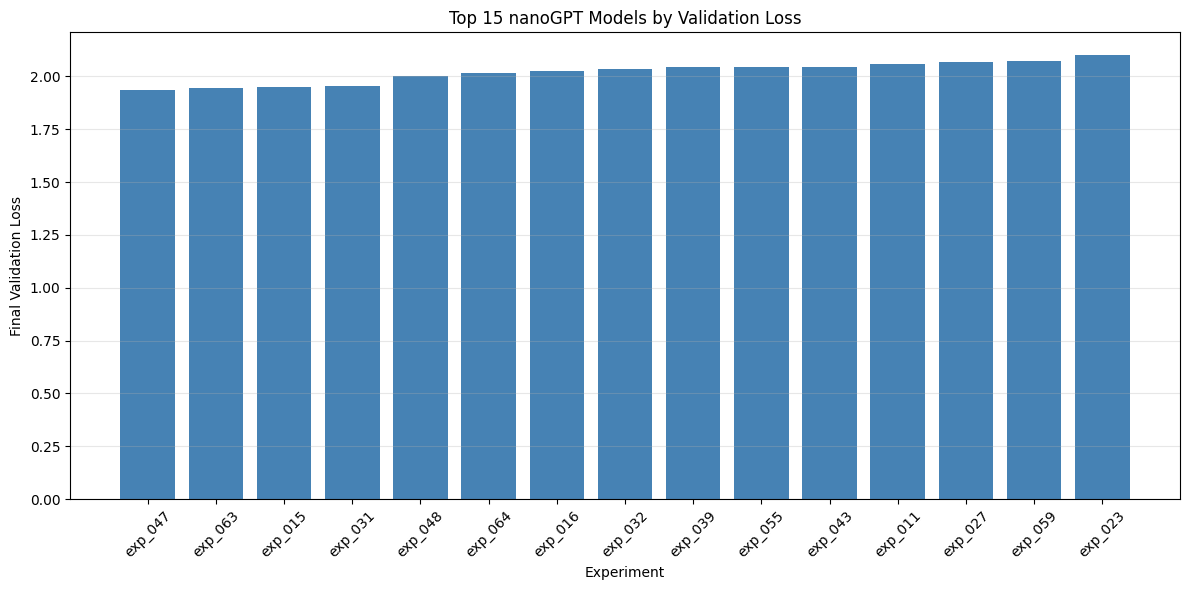

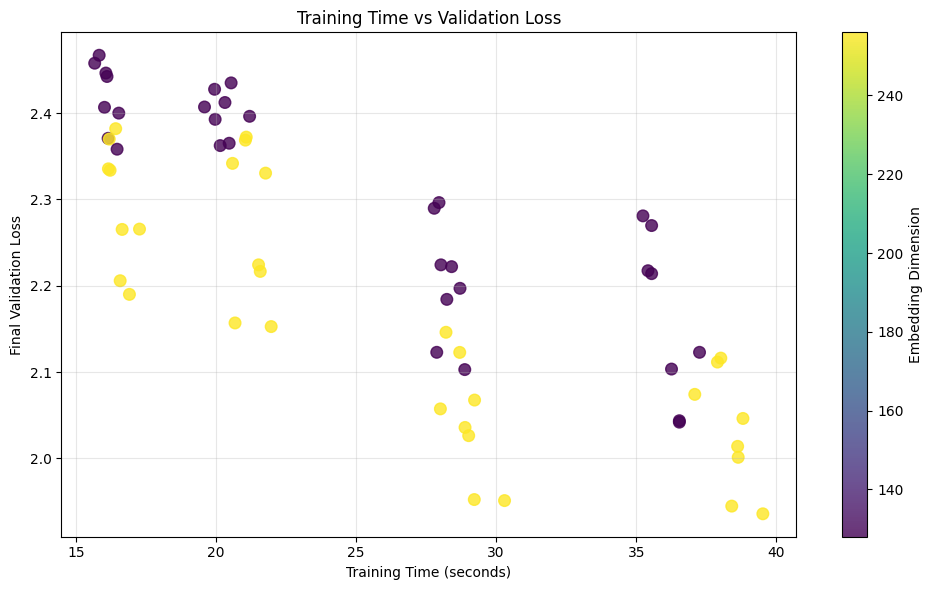

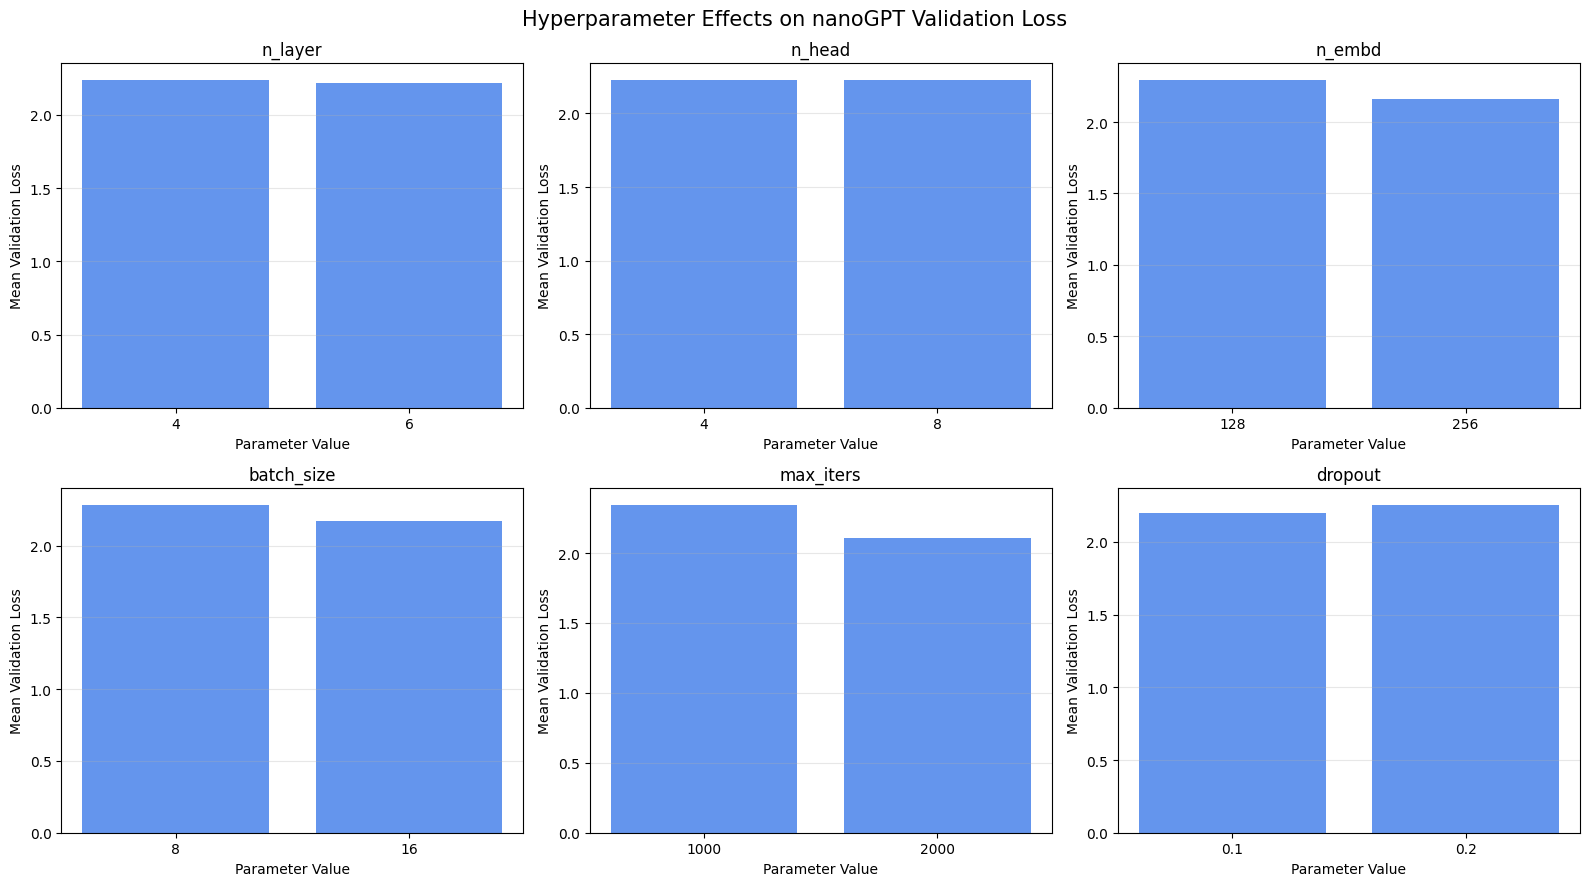

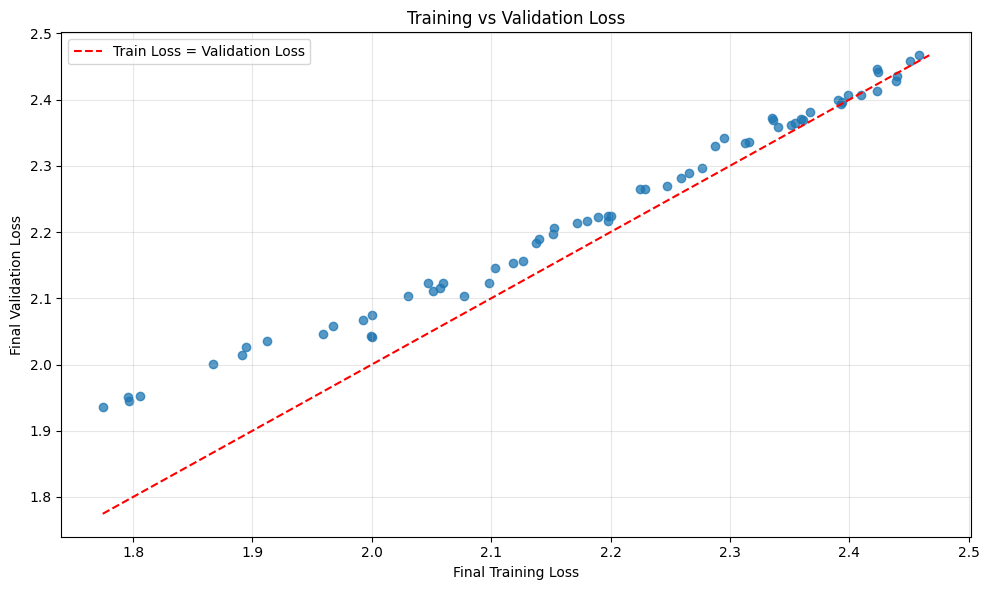

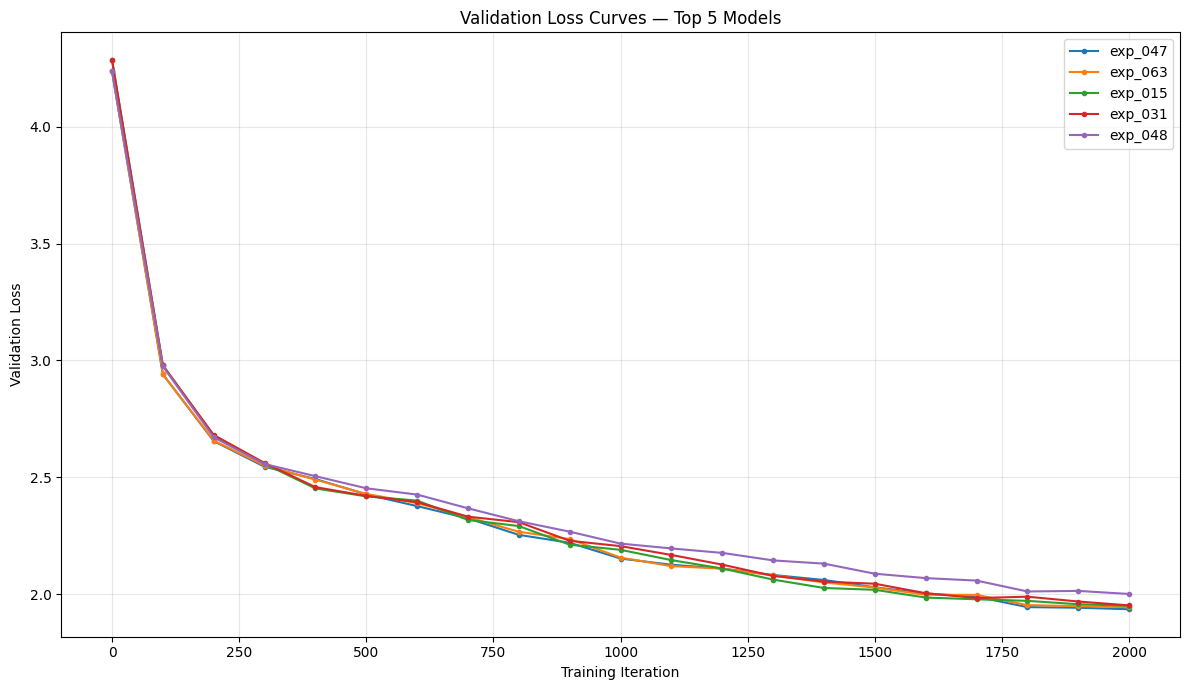


FINAL EXPERIMENT SUMMARY
---------------------------------------------
Completed: 64
Best experiment: exp_047
Best validation loss: 1.9359
Best training loss: 1.7746
Average validation loss: 2.228
Generalization gap: 0.1613

TOP 5 CONFIGURATIONS


,experiment_id,n_layer,n_head,n_embd,batch_size,max_iters,dropout,final_train_loss,final_val_loss
46,exp_047,6,4,256,16,2000,0.1,1.7746,1.9359
62,exp_063,6,8,256,16,2000,0.1,1.7966,1.9448
14,exp_015,4,4,256,16,2000,0.1,1.7954,1.9512
30,exp_031,4,8,256,16,2000,0.1,1.8055,1.9524
47,exp_048,6,4,256,16,2000,0.2,1.8673,2.0013



All graphs and CSV files saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import zipfile
from pathlib import Path
from IPython.display import display
from google.colab import files

# --------------------------------------------------
# 1. LOAD EXPERIMENT RESULTS
# --------------------------------------------------

ROOT = Path("/content/nanoGPT/experiment_results")
PLOTS = ROOT / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "member1_experiments.csv")
df = df[df["status"] == "completed"].copy()

df["generalization_gap"] = (
    df["final_val_loss"] - df["final_train_loss"]
)

print("Completed experiments:", len(df))
print("Total training time (minutes):",
      round(df["training_time_seconds"].sum() / 60, 2))

# --------------------------------------------------
# 2. EXTRACT LOSS CURVES FROM LOG FILES
# --------------------------------------------------

records = []

pattern = re.compile(
    r"step (\d+): train loss ([\d.]+), val loss ([\d.]+)"
)

for exp_id in df["experiment_id"]:
    log_path = ROOT / "logs" / f"{exp_id}.log"

    if not log_path.exists():
        print("Missing log:", exp_id)
        continue

    log_text = log_path.read_text()

    for step, train_loss, val_loss in pattern.findall(log_text):
        records.append({
            "experiment_id": exp_id,
            "step": int(step),
            "train_loss": float(train_loss),
            "val_loss": float(val_loss)
        })

curves = pd.DataFrame(records)

curves.to_csv(PLOTS / "loss_curves.csv", index=False)

# --------------------------------------------------
# 3. GRAPH 1: TOP 15 MODELS
# --------------------------------------------------

top15 = df.nsmallest(15, "final_val_loss")

plt.figure(figsize=(12, 6))
plt.bar(
    top15["experiment_id"],
    top15["final_val_loss"],
    color="steelblue"
)

plt.title("Top 15 nanoGPT Models by Validation Loss")
plt.xlabel("Experiment")
plt.ylabel("Final Validation Loss")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(PLOTS / "01_validation_ranking.png", dpi=300)
plt.show()

# --------------------------------------------------
# 4. GRAPH 2: TRAINING TIME VS VALIDATION LOSS
# --------------------------------------------------

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["training_time_seconds"],
    df["final_val_loss"],
    c=df["n_embd"],
    cmap="viridis",
    s=70,
    alpha=0.8
)

plt.colorbar(scatter, label="Embedding Dimension")
plt.title("Training Time vs Validation Loss")
plt.xlabel("Training Time (seconds)")
plt.ylabel("Final Validation Loss")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(PLOTS / "02_time_vs_loss.png", dpi=300)
plt.show()

# --------------------------------------------------
# 5. GRAPH 3: HYPERPARAMETER COMPARISON
# --------------------------------------------------

parameters = [
    "n_layer",
    "n_head",
    "n_embd",
    "batch_size",
    "max_iters",
    "dropout"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, parameter in zip(axes.flatten(), parameters):
    summary = df.groupby(parameter)["final_val_loss"].mean()

    ax.bar(
        summary.index.astype(str),
        summary.values,
        color="cornflowerblue"
    )

    ax.set_title(parameter)
    ax.set_xlabel("Parameter Value")
    ax.set_ylabel("Mean Validation Loss")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Hyperparameter Effects on nanoGPT Validation Loss",
    fontsize=15
)

plt.tight_layout()
plt.savefig(PLOTS / "03_hyperparameter_comparison.png", dpi=300)
plt.show()

# --------------------------------------------------
# 6. GRAPH 4: GENERALIZATION / OVERFITTING
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    df["final_train_loss"],
    df["final_val_loss"],
    alpha=0.75
)

low = min(
    df["final_train_loss"].min(),
    df["final_val_loss"].min()
)
high = max(
    df["final_train_loss"].max(),
    df["final_val_loss"].max()
)

plt.plot(
    [low, high],
    [low, high],
    "r--",
    label="Train Loss = Validation Loss"
)

plt.xlabel("Final Training Loss")
plt.ylabel("Final Validation Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(PLOTS / "04_generalization.png", dpi=300)
plt.show()

# --------------------------------------------------
# 7. GRAPH 5: BEST 5 MODEL LEARNING CURVES
# --------------------------------------------------

best5 = df.nsmallest(5, "final_val_loss")

plt.figure(figsize=(12, 7))

for exp_id in best5["experiment_id"]:
    exp_curve = curves[
        curves["experiment_id"] == exp_id
    ].sort_values("step")

    plt.plot(
        exp_curve["step"],
        exp_curve["val_loss"],
        marker="o",
        markersize=3,
        label=exp_id
    )

plt.title("Validation Loss Curves — Top 5 Models")
plt.xlabel("Training Iteration")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(PLOTS / "05_best_model_curves.png", dpi=300)
plt.show()

# --------------------------------------------------
# 8. EXPORT TABLES AND SUMMARY
# --------------------------------------------------

df.to_csv(
    PLOTS / "experiment_results_with_gap.csv",
    index=False
)

best = df.loc[df["final_val_loss"].idxmin()]

print("\nFINAL EXPERIMENT SUMMARY")
print("-" * 45)
print("Completed:", len(df))
print("Best experiment:", best["experiment_id"])
print("Best validation loss:", best["final_val_loss"])
print("Best training loss:", best["final_train_loss"])
print("Average validation loss:",
      round(df["final_val_loss"].mean(), 4))
print("Generalization gap:",
      round(best["generalization_gap"], 4))

print("\nTOP 5 CONFIGURATIONS")
display(
    best5[
        [
            "experiment_id",
            "n_layer",
            "n_head",
            "n_embd",
            "batch_size",
            "max_iters",
            "dropout",
            "final_train_loss",
            "final_val_loss"
        ]
    ]
)

# --------------------------------------------------
# 9. DOWNLOAD ALL GRAPHS AS ZIP
# --------------------------------------------------

zip_path = "/content/nanoGPT_graphs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in PLOTS.iterdir():
        if file.is_file():
            z.write(file, arcname=file.name)

print("\nAll graphs and CSV files saved!")
files.download(zip_path)


In [2]:

import os
import subprocess
import zipfile
from pathlib import Path
from google.colab import files

# 1. Restore nanoGPT repository
ROOT = Path("/content/nanoGPT")

if not (ROOT / "sample.py").exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/karpathy/nanoGPT.git",
         str(ROOT)],
        check=True
    )

# Use the same repository version as training
subprocess.run(
    ["git", "checkout", "3adf61e154c3fe3fca428ad6bc3818b27a3b8291"],
    cwd=str(ROOT),
    check=True
)

# 2. Install dependencies
subprocess.run(
    ["pip", "install", "-q", "tiktoken", "transformers"],
    check=True
)

# 3. Upload your final backup
print("Upload nanoGPT_final_backup.zip")
uploaded = files.upload()

backup_name = next(
    (name for name in uploaded
     if name.endswith("nanoGPT_final_backup.zip")),
    None
)

if backup_name is None:
    raise FileNotFoundError("Please upload nanoGPT_final_backup.zip")

# 4. Restore best model checkpoint
with zipfile.ZipFile(backup_name) as z:
    checkpoint_files = [
        name for name in z.namelist()
        if name.startswith("best_checkpoint/exp_047/")
    ]

    if not checkpoint_files:
        raise FileNotFoundError(
            "exp_047 checkpoint missing from backup"
        )

    for name in checkpoint_files:
        relative = Path(name).relative_to(
            "best_checkpoint/exp_047"
        )
        if not relative.parts or ".." in relative.parts:
            continue

        destination = (
            ROOT / "experiment_results" /
            "checkpoints" / "exp_047" / relative
        )
        destination.parent.mkdir(parents=True, exist_ok=True)

        if not name.endswith("/"):
            destination.write_bytes(z.read(name))

# 5. Restore Shakespeare character metadata
subprocess.run(
    ["python", "data/shakespeare_char/prepare.py"],
    cwd=str(ROOT),
    check=True
)

# 6. Generate Shakespeare text
checkpoint_dir = (
    ROOT / "experiment_results" /
    "checkpoints" / "exp_047"
)

command = [
    "python", "sample.py",
    f"--out_dir={checkpoint_dir}",
    "--num_samples=3",
    "--max_new_tokens=300",
    "--temperature=0.8",
    "--top_k=40",
    "--device=" + (
        "cuda" if __import__("torch").cuda.is_available()
        else "cpu"
    )
]

result = subprocess.run(
    command,
    cwd=str(ROOT),
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Text generation failed")

print(result.stdout)

# 7. Save and download generated text
output = ROOT / "exp_047_generated_text.txt"
output.write_text(result.stdout)

files.download(str(output))


Upload nanoGPT_final_backup.zip


Saving nanoGPT_final_backup.zip to nanoGPT_final_backup.zip
Overriding: out_dir = /content/nanoGPT/experiment_results/checkpoints/exp_047
Overriding: num_samples = 3
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 40
Overriding: device = cpu
number of parameters: 4.74M
Loading meta from data/shakespeare_char/meta.pkl...


VINCES:
Cone, his are like love thee seet roughter.

LOUCES:
Ter, I'll wourd mut and a mobe
All in on his our with pret a on love firs
him to to be unter leaver and the catce mort?

PRERINCA:
Would fellow'd, but the brond the a witt
Seep to let fating they, compition unce have

CALUS:
I hearnows of
---------------

Then firs, his by fairst ling her reper of in the fatne.

CALUKET:
Whe heav of a cret for peip, my nober of the be thing
Hat it by shold your good me him of the dept heave
The hands will that hos my actane'ss,
Who were sand till appiss. Where lirly to so.

DUCES:
You him bost bricking hing and
With 
---------------

KING H

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The best-performing model, exp_047, was tested with the top-k sampling of 40 samples and generation length of 300 tokens per sample and a temperature of 0.8. There were about 4.74 million parameters in the model.

The output showed some ability to learn Shakespearean dialogue style – speaker labels, punctuation and conversational structure. The text did have invented words, grammatical errors, and low level semantic coherency, however. The results indicate that the model was able to learn some structural properties of the training set and character-level properties, but not all meaningful long-range linguistic connections.

The final training loss of 1.7746 and final validation loss of 1.9359 were the lowest on the 64 experiments that were evaluated, making this the best performing one.